# Experiment 13 — Feature-space, correlation, and dimensionality analysis

This notebook analyzes Exp 9's winning 18 input features: the compact feature set, global 24-month target lag, town–flat-type historical mean, and nearest MRT/attraction/monument names.

All learned transformations are fit on the chronological fit period only. The validation period is used only to check whether an observed association persists. PCA/SVD is unsupervised; mutual information is supervised but estimated on fit rows only.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial import cKDTree
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_selection import mutual_info_regression, r_regression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

configured_root = os.environ.get('KDDM_PROJECT_ROOT')
roots = ([Path(configured_root)] if configured_root else []) + [Path.cwd(), *Path.cwd().parents]
project_root = next((root for root in roots if (root / 'exploration/metul/preprocessing.py').exists()), None)
if project_root is None:
    raise FileNotFoundError('Set KDDM_PROJECT_ROOT to the project directory.')
sys.path.insert(0, str(project_root / 'exploration' / 'metul'))
from preprocessing import RentalPreprocessor, load_datasets

TARGET = 'MONTHLY_RENT'
GROUP_COLUMNS = ['TOWN', 'FLAT_TYPE']
LAG_MONTHS = 24
N_COMPONENTS = 25
MI_SAMPLE = int(os.environ.get('FEATURE_MI_SAMPLE', '30000'))
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

compact_features = ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'approval_date_num', 'approval_month', 'coe_quota_premium_mean', 'YEAR_COMPLETED', 'MAX_FLOOR', 'mrt_dist_nearest_km', 'mall_dist_nearest_km']
BEST_FEATURES = compact_features + ['monthly_target_lag', 'town_flat_type_target_mean', 'nearest_mrt_name', 'nearest_tourist_attraction_name', 'nearest_monument_name']


In [2]:
class TargetFeatureTransformer:
    def fit(self, history):
        self.global_mean_ = history[TARGET].mean()
        self.group_mean_ = history.groupby(GROUP_COLUMNS)[TARGET].mean()
        self.monthly_mean_ = history.groupby('period')[TARGET].mean()
        return self

    def transform(self, frame):
        result = frame[GROUP_COLUMNS + ['period']].copy()
        result['monthly_target_lag'] = (result['period'] - LAG_MONTHS).map(self.monthly_mean_).fillna(self.global_mean_)
        group_mean = pd.Series(result.set_index(GROUP_COLUMNS).index.map(self.group_mean_), index=result.index)
        result['town_flat_type_target_mean'] = group_mean.fillna(self.global_mean_)
        return result[['monthly_target_lag', 'town_flat_type_target_mean']]

    def fit_transform_train(self, history):
        self.fit(history)
        grouped = history.groupby(GROUP_COLUMNS + ['period'], as_index=False)[TARGET].agg(['sum', 'count']).reset_index().sort_values(GROUP_COLUMNS + ['period'])
        grouped['prior_sum'] = grouped.groupby(GROUP_COLUMNS)['sum'].cumsum() - grouped['sum']
        grouped['prior_count'] = grouped.groupby(GROUP_COLUMNS)['count'].cumsum() - grouped['count']
        grouped['town_flat_type_target_mean'] = grouped['prior_sum'] / grouped['prior_count'].replace(0, np.nan)
        global_monthly = history.groupby('period')[TARGET].agg(['sum', 'count']).sort_index()
        global_prior = (global_monthly['sum'].cumsum() - global_monthly['sum']) / (global_monthly['count'].cumsum() - global_monthly['count']).replace(0, np.nan)
        result = history[GROUP_COLUMNS + ['period']].merge(grouped[GROUP_COLUMNS + ['period', 'town_flat_type_target_mean']], on=GROUP_COLUMNS + ['period'], how='left')
        result['town_flat_type_target_mean'] = result['town_flat_type_target_mean'].fillna(result['period'].map(global_prior))
        result['monthly_target_lag'] = (result['period'] - LAG_MONTHS).map(self.monthly_mean_).fillna(result['period'].map(global_prior))
        return result[['monthly_target_lag', 'town_flat_type_target_mean']]

def nearest_mrt_name(base):
    stations = datasets['mrt'][['NAME', 'LATITUDE', 'LONGITUDE']].dropna()
    _, index = cKDTree(stations[['LATITUDE', 'LONGITUDE']].to_numpy() * [111.0, 110.96]).query(base[['LATITUDE', 'LONGITUDE']].to_numpy() * [111.0, 110.96])
    return pd.Series(stations['NAME'].astype(object).to_numpy()[index], name='nearest_mrt_name')

def nearest_geojson_name(base, filename, field, name):
    with (project_root / 'data' / 'possible_additional_features' / filename).open() as handle:
        data = json.load(handle)
    points = pd.DataFrame([
        {'longitude': item['geometry']['coordinates'][0], 'latitude': item['geometry']['coordinates'][1], name: item['properties'][field]}
        for item in data['features'] if item.get('geometry', {}).get('type') == 'Point'
    ]).dropna()
    _, index = cKDTree(points[['longitude', 'latitude']].to_numpy() * [110.96, 111.0]).query(base[['LONGITUDE', 'LATITUDE']].to_numpy() * [110.96, 111.0])
    return pd.Series(points[name].astype(object).to_numpy()[index], name=name)

def build_best_features(history_raw, future_raw):
    processor = RentalPreprocessor(datasets)
    history_base = processor.fit_transform(history_raw.drop(columns=['period', TARGET], errors='ignore'))
    future_base = processor.transform(future_raw.drop(columns=['period', TARGET], errors='ignore'))
    history = history_base[GROUP_COLUMNS].reset_index(drop=True).assign(period=history_raw['period'].to_numpy(), **{TARGET: history_raw[TARGET].to_numpy()})
    future = future_base[GROUP_COLUMNS].reset_index(drop=True).assign(period=future_raw['period'].to_numpy())
    target_features = TargetFeatureTransformer()
    history_target = target_features.fit_transform_train(history)
    future_target = target_features.transform(future)
    def combine(base, target):
        return pd.concat([
            base[compact_features].reset_index(drop=True), target.reset_index(drop=True),
            nearest_mrt_name(base).reset_index(drop=True),
            nearest_geojson_name(base, 'TouristAttractions.geojson', 'PAGETITLE', 'nearest_tourist_attraction_name').reset_index(drop=True),
            nearest_geojson_name(base, 'MonumentsGEOJSON.geojson', 'NAME', 'nearest_monument_name').reset_index(drop=True),
        ], axis=1)[BEST_FEATURES]
    return combine(history_base, history_target), combine(future_base, future_target)


In [3]:
_, datasets = load_datasets(project_root / 'data')
raw = datasets['train'].copy()
raw['period'] = pd.to_datetime(raw['RENT_APPROVAL_DATE'] + '-01').dt.to_period('M')
periods = np.sort(raw['period'].unique())
cutoff = periods[int(len(periods) * 0.80)]
raw_fit = raw.loc[raw['period'] < cutoff].copy()
raw_valid = raw.loc[raw['period'] >= cutoff].copy()
fit_x, valid_x = build_best_features(raw_fit, raw_valid)
fit_y = raw_fit[TARGET].astype(float).reset_index(drop=True)
valid_y = raw_valid[TARGET].astype(float).reset_index(drop=True)
assert list(fit_x.columns) == BEST_FEATURES == list(valid_x.columns)
print(f'Cutoff={cutoff}; fit={fit_x.shape}; validation={valid_x.shape}')
display(fit_x.head())


[categorical_clean] HDB lookup | TOWN: 26 -> 26 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | BLOCK: 2735 -> 2735 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | STREET: 576 -> 576 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | POSTAL_CODE: 9180 -> 9180 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | SUBZONE: 156 -> 156 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | PLANNING_AREA: 31 -> 31 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces


,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,approval_date_num,approval_month,coe_quota_premium_mean,YEAR_COMPLETED,MAX_FLOOR,mrt_dist_nearest_km,mall_dist_nearest_km,monthly_target_lag,town_flat_type_target_mean,nearest_mrt_name,nearest_tourist_attraction_name,nearest_monument_name
0,punggol,604a,punggol road,4 room,model a,93.0,24253,1,45187.375,2010,16,0.555635,0.650683,NaN,NaN,punggol mrt/lrt station,The Japanese Cemetery Park,Church of the Nativity of the Blessed Virgin Mary
1,sengkang,290c,compassvale crescent,5 room,improved,110.0,24253,1,45187.375,2000,15,0.633253,0.615214,NaN,NaN,sengkang mrt/lrt station,The Japanese Cemetery Park,Church of the Nativity of the Blessed Virgin Mary
2,queenstown,5,ghim moh road,3 room,improved,65.0,24253,1,45187.375,1975,15,0.624787,0.603773,NaN,NaN,buona vista mrt station,"NUS University Museum, Singapore",Chinese High School Clock Tower
3,sengkang,436b,fernvale road,4 room,model a,96.0,24253,1,45187.375,2008,21,2.066014,0.182555,NaN,NaN,sengkang mrt/lrt station,The Japanese Cemetery Park,Church of the Nativity of the Blessed Virgin Mary
4,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,24253,1,45187.375,1999,16,0.760948,0.729008,NaN,NaN,sembawang mrt station,Singapore Zoo: Attractions & Things to Do,Former Admiralty House


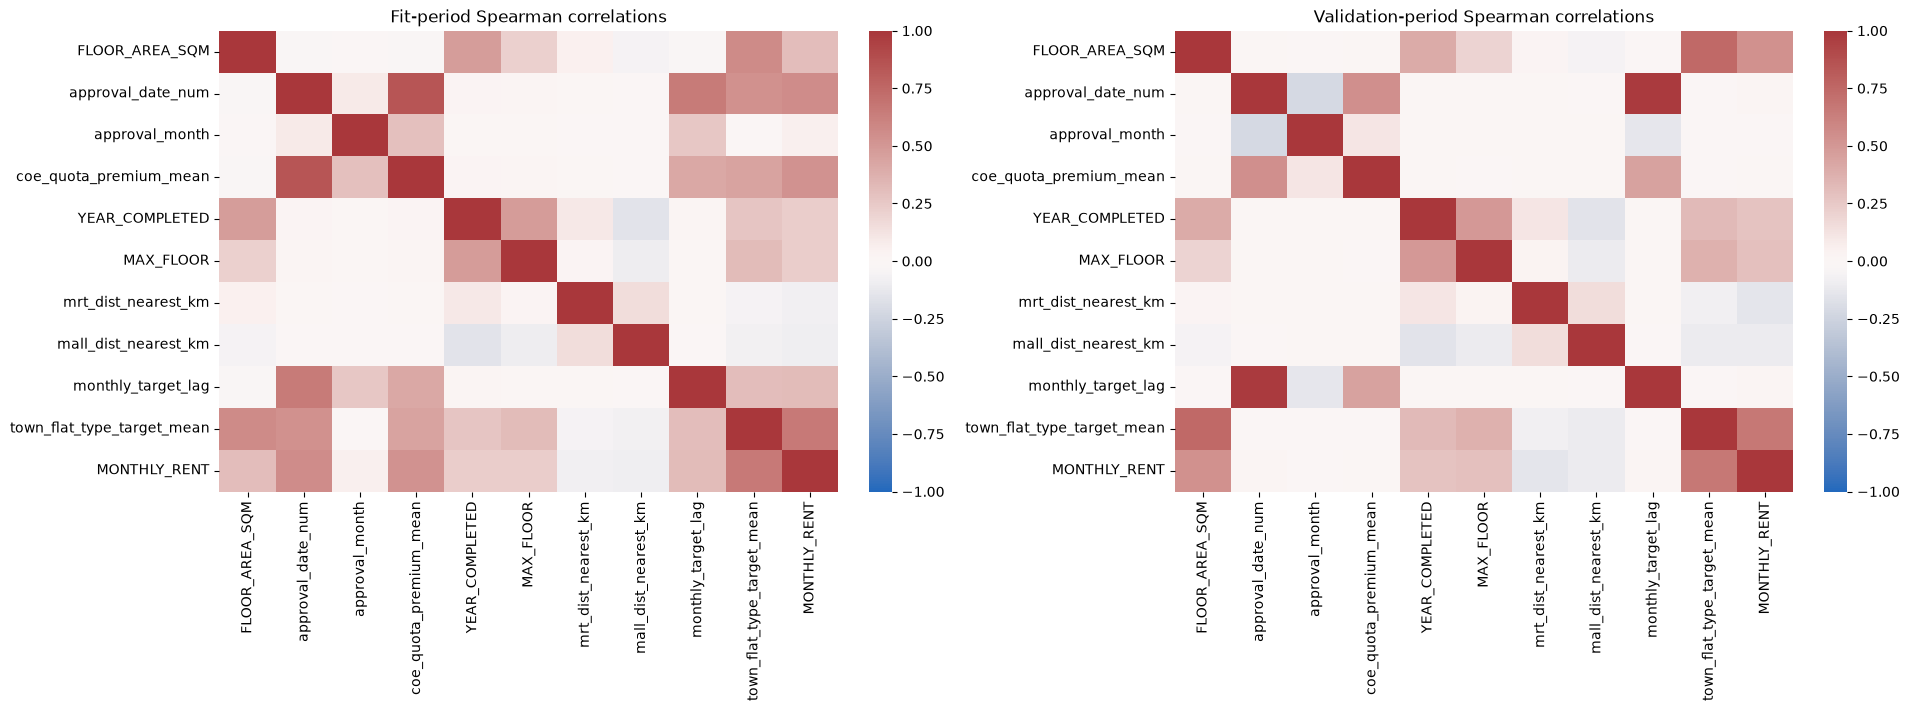

,fit_pearson,fit_spearman,validation_pearson,validation_spearman,absolute_stability
town_flat_type_target_mean,0.669953,0.663695,0.651859,0.668246,0.004551
approval_date_num,0.545515,0.562226,0.016145,0.017877,0.544349
coe_quota_premium_mean,0.518957,0.528425,-0.001656,0.005706,0.522719
monthly_target_lag,0.298680,0.317593,0.015280,0.016288,0.301305
FLOOR_AREA_SQM,0.314313,0.308192,0.498232,0.532147,0.223955
YEAR_COMPLETED,0.073630,0.228823,0.236322,0.278863,0.050040
MAX_FLOOR,0.286167,0.227813,0.354069,0.290231,0.062418
mall_dist_nearest_km,-0.082897,-0.090170,-0.101847,-0.109099,0.018929
mrt_dist_nearest_km,-0.079093,-0.085130,-0.137330,-0.144300,0.059170
approval_month,0.054020,0.055160,-0.002921,-0.003078,0.058239


,component,explained_variance_ratio,fit_target_correlation,validation_target_correlation,abs_fit_correlation
0,1,0.272714,0.653948,0.305883,0.653948
1,2,0.159151,0.262449,0.559979,0.262449
7,8,0.061130,-0.123605,0.020205,0.123605
2,3,0.107514,-0.089196,-0.174234,0.089196
3,4,0.104531,0.067688,0.138812,0.067688
8,9,0.022017,0.060717,0.195395,0.060717
6,7,0.081973,0.031111,0.084670,0.031111
4,5,0.095234,-0.022494,0.148018,0.022494
5,6,0.089713,-0.012560,-0.010980,0.012560
9,10,0.006024,-0.010919,-0.087880,0.010919


In [4]:
numeric_columns = fit_x.select_dtypes(include=np.number).columns.tolist()
fit_numeric = fit_x[numeric_columns].copy()
valid_numeric = valid_x[numeric_columns].copy()
fit_numeric[TARGET] = fit_y
valid_numeric[TARGET] = valid_y

fig, axes = plt.subplots(1, 2, figsize=(19, 7), constrained_layout=True)
sns.heatmap(fit_numeric.corr(method='spearman'), cmap='vlag', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Fit-period Spearman correlations')
sns.heatmap(valid_numeric.corr(method='spearman'), cmap='vlag', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Validation-period Spearman correlations')
plt.show()

numeric_summary = pd.DataFrame({
    'fit_pearson': fit_numeric.corrwith(fit_y, method='pearson').drop(TARGET),
    'fit_spearman': fit_numeric.corrwith(fit_y, method='spearman').drop(TARGET),
    'validation_pearson': valid_numeric.corrwith(valid_y, method='pearson').drop(TARGET),
    'validation_spearman': valid_numeric.corrwith(valid_y, method='spearman').drop(TARGET),
})
numeric_summary['absolute_stability'] = (numeric_summary['fit_spearman'] - numeric_summary['validation_spearman']).abs()
display(numeric_summary.reindex(numeric_summary['fit_spearman'].abs().sort_values(ascending=False).index))

# Ordinary PCA is meaningful for the standardized numeric portion only.
numeric_pca = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('pca', PCA(n_components=min(len(numeric_columns), 10), random_state=RANDOM_STATE))])
fit_numeric_pca = numeric_pca.fit_transform(fit_x[numeric_columns])
valid_numeric_pca = numeric_pca.transform(valid_x[numeric_columns])
pca_summary = pd.DataFrame({
    'component': np.arange(1, fit_numeric_pca.shape[1] + 1),
    'explained_variance_ratio': numeric_pca.named_steps['pca'].explained_variance_ratio_,
    'fit_target_correlation': [np.corrcoef(fit_numeric_pca[:, index], fit_y)[0, 1] for index in range(fit_numeric_pca.shape[1])],
    'validation_target_correlation': [np.corrcoef(valid_numeric_pca[:, index], valid_y)[0, 1] for index in range(valid_numeric_pca.shape[1])],
})
display(pca_summary.assign(abs_fit_correlation=lambda frame: frame.fit_target_correlation.abs()).sort_values('abs_fit_correlation', ascending=False))


In [5]:
categorical_columns = [column for column in BEST_FEATURES if column not in numeric_columns]
encoder = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_columns),
    ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_columns),
])
fit_encoded = encoder.fit_transform(fit_x)
valid_encoded = encoder.transform(valid_x)
feature_names = encoder.get_feature_names_out()
print(f'Encoded feature space: {fit_encoded.shape[1]:,} columns; density={fit_encoded.nnz / (fit_encoded.shape[0] * fit_encoded.shape[1]):.4%}')

# Correlation of every one-hot / numeric transformed column with target.
fit_encoded_corr = r_regression(fit_encoded, fit_y.to_numpy(), force_finite=True)
valid_encoded_corr = r_regression(valid_encoded, valid_y.to_numpy(), force_finite=True)
encoded_correlations = pd.DataFrame({'encoded_feature': feature_names, 'fit_correlation': fit_encoded_corr, 'validation_correlation': valid_encoded_corr})
encoded_correlations['abs_fit_correlation'] = encoded_correlations['fit_correlation'].abs()
display(encoded_correlations.nlargest(25, 'abs_fit_correlation'))

def source_feature(name):
    if name.startswith('numeric__'):
        return name.removeprefix('numeric__')
    return next((column for column in categorical_columns if name.startswith(f'categorical__{column}_')), 'other')

encoded_correlations['source_feature'] = encoded_correlations['encoded_feature'].map(source_feature)
grouped_association = encoded_correlations.groupby('source_feature').agg(max_abs_fit_correlation=('abs_fit_correlation', 'max'), mean_abs_fit_correlation=('abs_fit_correlation', 'mean'), max_abs_validation_correlation=('validation_correlation', lambda values: values.abs().max())).sort_values('max_abs_fit_correlation', ascending=False)
display(grouped_association)

svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
fit_svd = svd.fit_transform(fit_encoded)
valid_svd = svd.transform(valid_encoded)
svd_summary = pd.DataFrame({
    'component': np.arange(1, N_COMPONENTS + 1),
    'explained_variance_ratio': svd.explained_variance_ratio_,
    'fit_target_correlation': [np.corrcoef(fit_svd[:, index], fit_y)[0, 1] for index in range(N_COMPONENTS)],
    'validation_target_correlation': [np.corrcoef(valid_svd[:, index], valid_y)[0, 1] for index in range(N_COMPONENTS)],
})
display(svd_summary.assign(abs_fit_correlation=lambda frame: frame.fit_target_correlation.abs()).sort_values('abs_fit_correlation', ascending=False))


Encoded feature space: 3,556 columns; density=0.5062%


,encoded_feature,fit_correlation,validation_correlation,abs_fit_correlation
9,numeric__town_flat_type_target_mean,0.664754,0.651859,0.664754
1,numeric__approval_date_num,0.545515,0.016145,0.545515
3,numeric__coe_quota_premium_mean,0.518957,-0.001656,0.518957
0,numeric__FLOOR_AREA_SQM,0.314313,0.498232,0.314313
8,numeric__monthly_target_lag,0.299739,0.015280,0.299739
3311,categorical__FLAT_TYPE_3 room,-0.297961,-0.431098,0.297961
5,numeric__MAX_FLOOR,0.286167,0.354069,0.286167
3313,categorical__FLAT_TYPE_5 room,0.188474,0.286602,0.188474
3325,categorical__FLAT_MODEL_new generation,-0.143511,-0.199627,0.143511
3310,categorical__FLAT_TYPE_2 room,-0.136218,-0.230374,0.136218


,max_abs_fit_correlation,mean_abs_fit_correlation,max_abs_validation_correlation
source_feature,,,
town_flat_type_target_mean,0.664754,0.664754,0.651859
approval_date_num,0.545515,0.545515,0.016145
coe_quota_premium_mean,0.518957,0.518957,0.001656
FLOOR_AREA_SQM,0.314313,0.314313,0.498232
monthly_target_lag,0.299739,0.299739,0.015280
FLAT_TYPE,0.297961,0.144633,0.431098
MAX_FLOOR,0.286167,0.286167,0.354069
FLAT_MODEL,0.143511,0.047244,0.199627
STREET,0.128478,0.010731,0.157029


,component,explained_variance_ratio,fit_target_correlation,validation_target_correlation,abs_fit_correlation
0,1,0.159556,0.668739,0.349349,0.668739
1,2,0.103755,0.208932,0.541843,0.208932
8,9,0.035458,-0.126951,0.016735,0.126951
2,3,0.063826,-0.107206,-0.220437,0.107206
7,8,0.005663,0.069583,0.166947,0.069583
4,5,0.056408,-0.066750,0.034387,0.066750
11,12,0.018986,0.041795,0.175170,0.041795
10,11,0.019321,0.040247,0.112346,0.040247
12,13,0.015086,0.031564,0.114624,0.031564
6,7,0.050010,-0.030719,-0.139670,0.030719


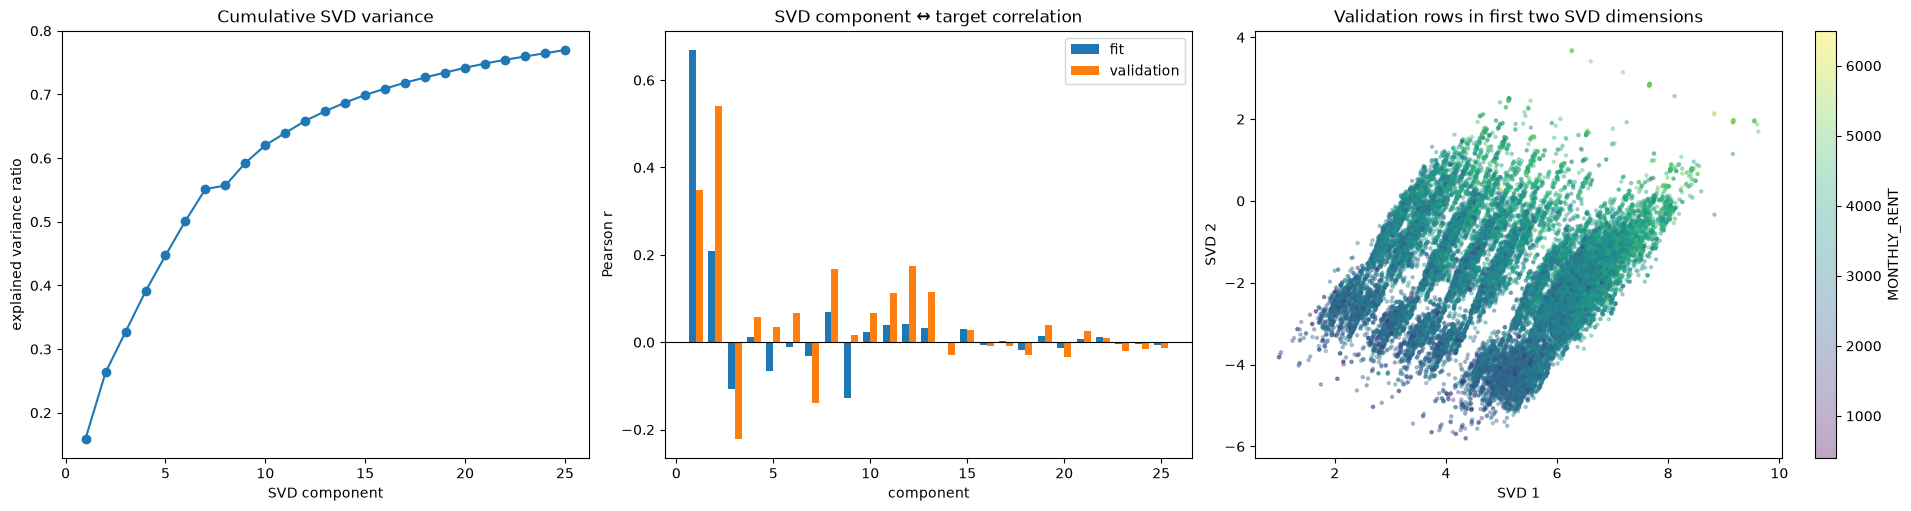

Component 1: fit r=0.669, validation r=0.349


,loading
numeric__approval_date_num,0.537591
numeric__coe_quota_premium_mean,0.496461
numeric__town_flat_type_target_mean,0.456287
numeric__monthly_target_lag,0.410647
numeric__FLOOR_AREA_SQM,0.162868
numeric__MAX_FLOOR,0.151799
numeric__approval_month,0.141540
categorical__FLAT_TYPE_3 room,-0.079032
numeric__YEAR_COMPLETED,0.066753
categorical__FLAT_TYPE_5 room,0.044032


Component 2: fit r=0.209, validation r=0.542


,loading
numeric__FLOOR_AREA_SQM,0.568745
numeric__MAX_FLOOR,0.391803
numeric__town_flat_type_target_mean,0.359980
numeric__coe_quota_premium_mean,-0.253499
numeric__approval_date_num,-0.247756
categorical__FLAT_TYPE_3 room,-0.247587
numeric__monthly_target_lag,-0.226329
numeric__YEAR_COMPLETED,0.213631
numeric__approval_month,-0.157102
categorical__FLAT_TYPE_5 room,0.156447


Component 9: fit r=-0.127, validation r=0.017


,loading
numeric__monthly_target_lag,0.842484
numeric__coe_quota_premium_mean,-0.511781
numeric__approval_date_num,-0.134669
numeric__approval_month,-0.064841
numeric__town_flat_type_target_mean,-0.046301
numeric__FLOOR_AREA_SQM,0.034263
numeric__MAX_FLOOR,0.028999
categorical__FLAT_TYPE_5 room,0.019260
numeric__mrt_dist_nearest_km,-0.017714
categorical__FLAT_MODEL_improved,0.014969


Component 3: fit r=-0.107, validation r=-0.220


,loading
numeric__mrt_dist_nearest_km,0.793666
numeric__YEAR_COMPLETED,0.446697
numeric__mall_dist_nearest_km,0.204210
numeric__town_flat_type_target_mean,-0.161554
numeric__approval_month,0.151442
categorical__nearest_tourist_attraction_name_The Japanese Cemetery Park,0.119692
categorical__nearest_monument_name_Church of the Nativity of the Blessed Virgin Mary,0.115251
categorical__FLAT_MODEL_model a,0.104519
categorical__FLAT_TYPE_4 room,0.078176
numeric__MAX_FLOOR,0.078140


Component 8: fit r=0.070, validation r=0.167


,loading
categorical__FLAT_TYPE_4 room,0.450118
categorical__FLAT_MODEL_model a,0.360632
categorical__FLAT_MODEL_improved,0.334401
categorical__FLAT_TYPE_3 room,0.317832
categorical__FLAT_TYPE_5 room,0.258215
categorical__nearest_tourist_attraction_name_The Japanese Cemetery Park,0.233162
numeric__mrt_dist_nearest_km,-0.189258
categorical__FLAT_MODEL_new generation,0.186611
categorical__nearest_monument_name_Church of the Nativity of the Blessed Virgin Mary,0.158750
numeric__mall_dist_nearest_km,0.142082


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)
axes[0].plot(np.arange(1, N_COMPONENTS + 1), np.cumsum(svd.explained_variance_ratio_), marker='o')
axes[0].set(title='Cumulative SVD variance', xlabel='SVD component', ylabel='explained variance ratio')
axes[1].bar(svd_summary['component'] - 0.18, svd_summary['fit_target_correlation'], width=0.36, label='fit')
axes[1].bar(svd_summary['component'] + 0.18, svd_summary['validation_target_correlation'], width=0.36, label='validation')
axes[1].axhline(0, color='black', linewidth=0.8); axes[1].legend(); axes[1].set(title='SVD component ↔ target correlation', xlabel='component', ylabel='Pearson r')
scatter = axes[2].scatter(valid_svd[:, 0], valid_svd[:, 1], c=valid_y, s=5, alpha=0.35, cmap='viridis')
axes[2].set(title='Validation rows in first two SVD dimensions', xlabel='SVD 1', ylabel='SVD 2')
fig.colorbar(scatter, ax=axes[2], label='MONTHLY_RENT')
plt.show()

# The largest absolute loading identifies which original encoded features form a component.
for component in svd_summary.assign(abs_correlation=lambda frame: frame.fit_target_correlation.abs()).nlargest(5, 'abs_correlation')['component']:
    loadings = pd.Series(svd.components_[component - 1], index=feature_names)
    print(f"Component {component}: fit r={svd_summary.loc[component - 1, 'fit_target_correlation']:.3f}, validation r={svd_summary.loc[component - 1, 'validation_target_correlation']:.3f}")
    display(loadings.reindex(loadings.abs().nlargest(12).index).to_frame('loading'))


,feature,mutual_information
9,town_flat_type_target_mean,0.360833
1,approval_date_num,0.228769
3,coe_quota_premium_mean,0.217879
8,monthly_target_lag,0.194674
12,STREET,0.130312
0,FLOOR_AREA_SQM,0.097541
11,BLOCK,0.084781
13,FLAT_TYPE,0.082298
15,nearest_mrt_name,0.062681
5,MAX_FLOOR,0.056854


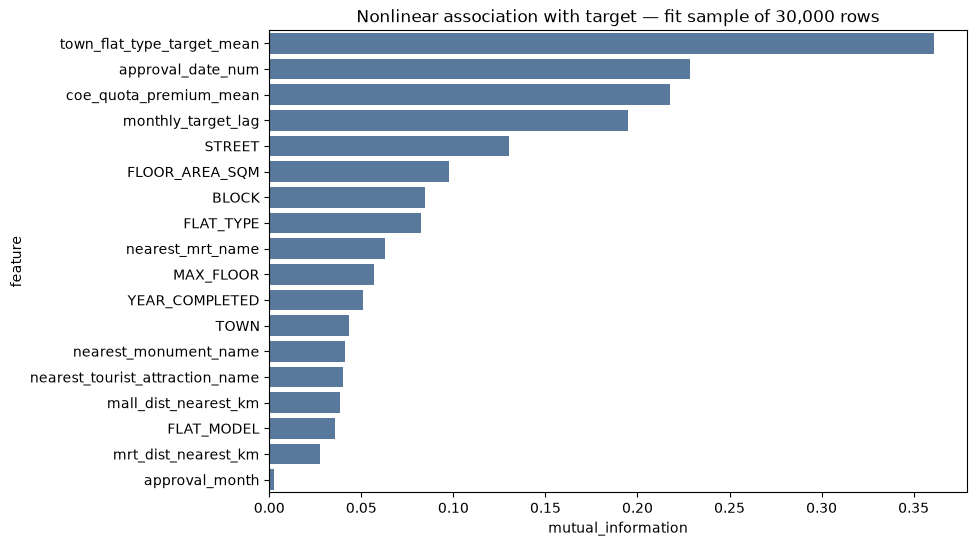

In [7]:
# Mutual information detects non-linear / non-monotonic dependence. It has no sign and is estimated only on a fit-period sample.
mi_encoder = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median'))]), numeric_columns),
    ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))]), categorical_columns),
])
sample_size = min(MI_SAMPLE, len(fit_x))
sample_index = fit_x.sample(sample_size, random_state=RANDOM_STATE).index
mi_x = mi_encoder.fit_transform(fit_x.loc[sample_index])
discrete_mask = np.array([False] * len(numeric_columns) + [True] * len(categorical_columns))
mi_values = mutual_info_regression(mi_x, fit_y.loc[sample_index], discrete_features=discrete_mask, random_state=RANDOM_STATE)
mi_summary = pd.DataFrame({'feature': numeric_columns + categorical_columns, 'mutual_information': mi_values}).sort_values('mutual_information', ascending=False)
display(mi_summary)
plt.figure(figsize=(9, 6))
sns.barplot(mi_summary, x='mutual_information', y='feature', color='#4c78a8')
plt.title(f'Nonlinear association with target — fit sample of {sample_size:,} rows')
plt.show()

# Interpretation: prioritize features/components whose target association is sizeable AND similar on validation.
# PCA/SVD may expose structure but does not inherently improve a tree model; use it only if a validation model confirms value.
